## Introduction
This notebook will perform extensive data analysis regarding bird bioacoustic monitoring. The data will be taken from the article "Automated identification of individual birds by song enables multi-year recapture from passive acoustic monitoring data", and it is located under resources/localized_events.csv. 

In [241]:
# First, we must import the necessary packages and libraries
import pandas as pd
import ast
import matplotlib as mpl
import numpy as np
from pathlib import Path 
from plotnine import ( 
    ggplot, 
    aes, 
    geom_point,
    geom_bar,
    facet_wrap,
    labs,
    scale_fill_manual,
    theme_minimal
)

Then, we will need to load in the data as a dataframe or just fetch the binary if it exists

In [242]:
path = Path("resources/localized_events.parquet")

if path.exists():
    print("Exists, so just load in binary file")
    all_loaded_events_df = pd.read_parquet("resources/localized_events.parquet")
else:
    print("Does not exist, so we create it")
    all_loaded_events_df = pd.read_csv("resources/localized_events.csv")
    all_loaded_events_df.to_parquet("resources/localized_events.parquet")


Exists, so just load in binary file


Now, we will take a subset of the column variables in the data spreadsheet.

In [243]:
subst_loaded_events_df = all_loaded_events_df[
    [
    # Metadata
    'array',
    'data_split',
    'relative_position',
    'mic_distances_m',
    'start_timestamp',
    'duration',

    # Automated models
    'ovenbird_cluster_labels',
    'baseline_resnet18_cluster_labels',
    'hawkears_cluster_labels',
    'birdnet_cluster_labels',
    ]
]

### Exploratory Data Analysis
We will begin by exploring the distributions of the data to identify possible outliers, trends, and occurrences. 

In [244]:
# add a new column individual so it does not conflict with python
subst_loaded_events_df['individual'] = all_loaded_events_df['class']

# Convert to datetime objects
subst_loaded_events_df['start_timestamp'] = pd.to_datetime(subst_loaded_events_df['start_timestamp'], utc=True)
subst_loaded_events_df['duration'] = pd.to_timedelta(subst_loaded_events_df['duration'], unit='minute')

In [245]:
# Create a new column just for the end_timestamp
subst_loaded_events_df['end_timestamp'] = (subst_loaded_events_df['start_timestamp'] + subst_loaded_events_df['duration'])

In [246]:
# Set an event key for all the rows
subst_loaded_events_df['event_key'] = range(len(subst_loaded_events_df))

In [247]:
# .value_counts() creates a lookup table, (individual: counts) for all individuals
# .map() takes that lookup table and assigns it to those individuals using 'individual' as the key
# This new column 'count' is assigned with that counts for each individual
lookup_individual_counts = subst_loaded_events_df['individual'].value_counts()
subst_loaded_events_df['count'] = subst_loaded_events_df['individual'].map(
    lookup_individual_counts
)

In [248]:
# Save to under resources
subst_loaded_events_df.to_parquet('resources/subset_loaded_events.parquet')
subst_loaded_events_df.to_csv('resources/subset_loaded_events.csv')

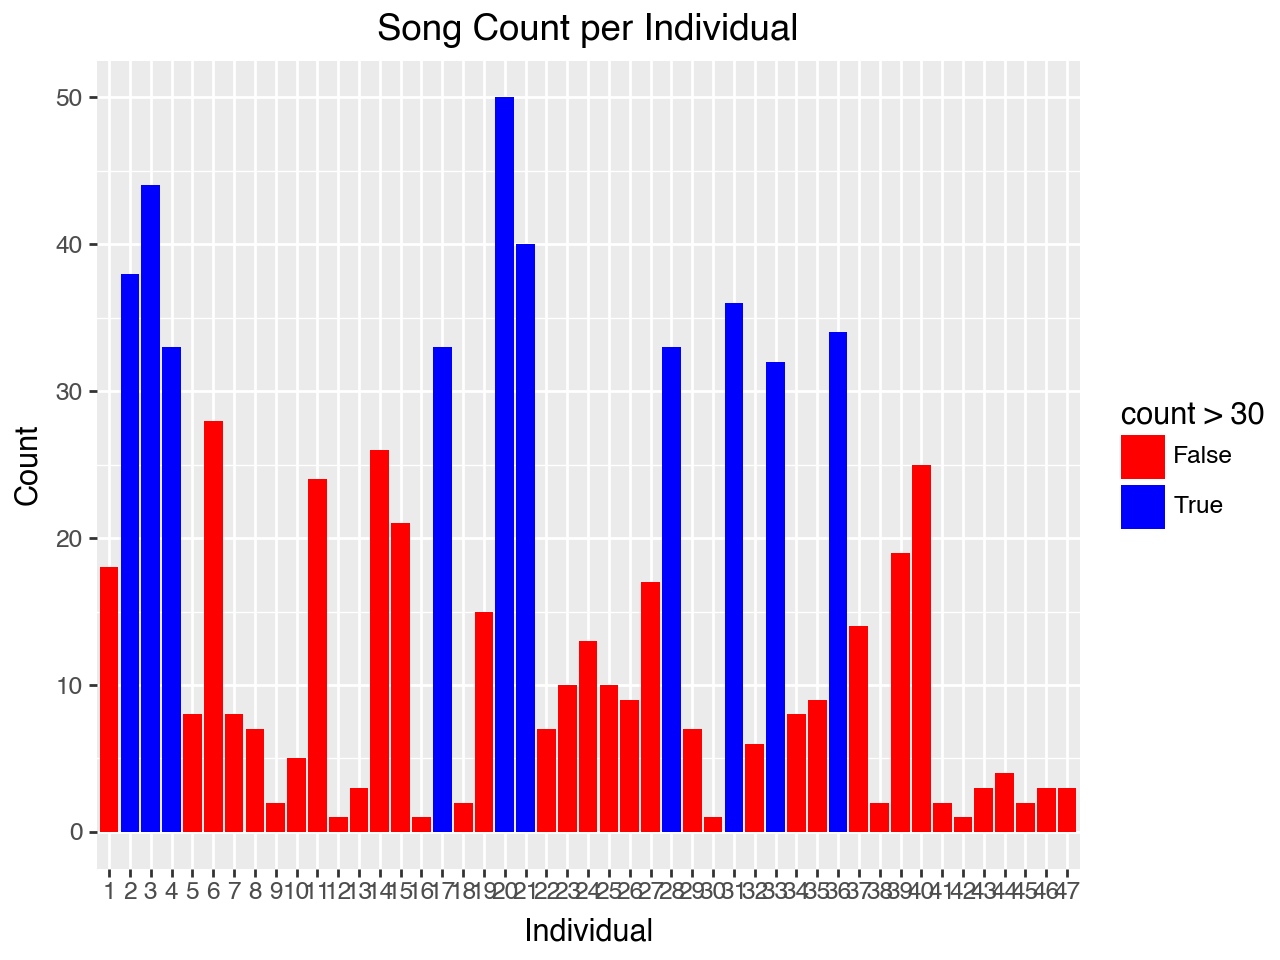

In [249]:
# Creates a ggplot object 
(
    ggplot(subst_loaded_events_df, aes(x='factor(individual)', fill='count > 30'))
    + geom_bar()
    + scale_fill_manual(
        values={True: 'blue', False: 'red'}
    )
    + labs(
        title='Song Count per Individual',
        x='Individual',
        y='Count'
    )
)

Now, we want to plot the recordings according to the relative (x, y) coordinates, they will be labeled according to the individual they belong to & faceted by the sites they belong to.

In [250]:
# Create the figure for this, using ast package to unpack the str
fig_df = pd.DataFrame()
fig_df['x'] = subst_loaded_events_df['relative_position'].apply(
    lambda p: ast.literal_eval(p)[0]
)
fig_df['y'] = subst_loaded_events_df['relative_position'].apply(
    lambda p: ast.literal_eval(p)[1]
)
fig_df['individual'] = subst_loaded_events_df['individual'].astype("category")

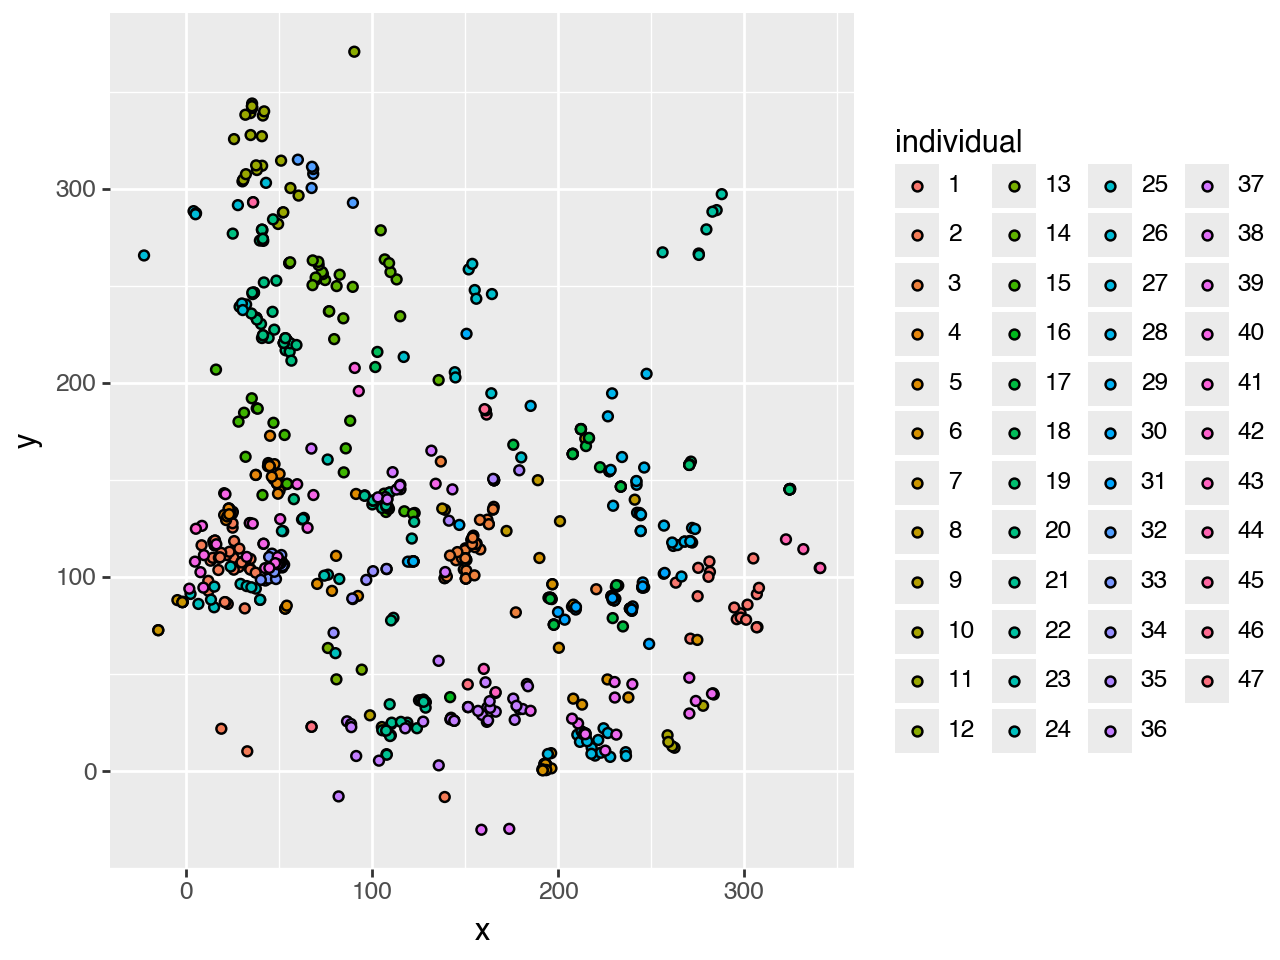

In [251]:
(
    ggplot(fig_df, aes('x', 'y', fill = 'individual')) +
        geom_point() 
)

Now, we will facet grid them by the site.

In [252]:
# Introduce the site column to enable facet gridding
fig_df['site'] = subst_loaded_events_df['array']

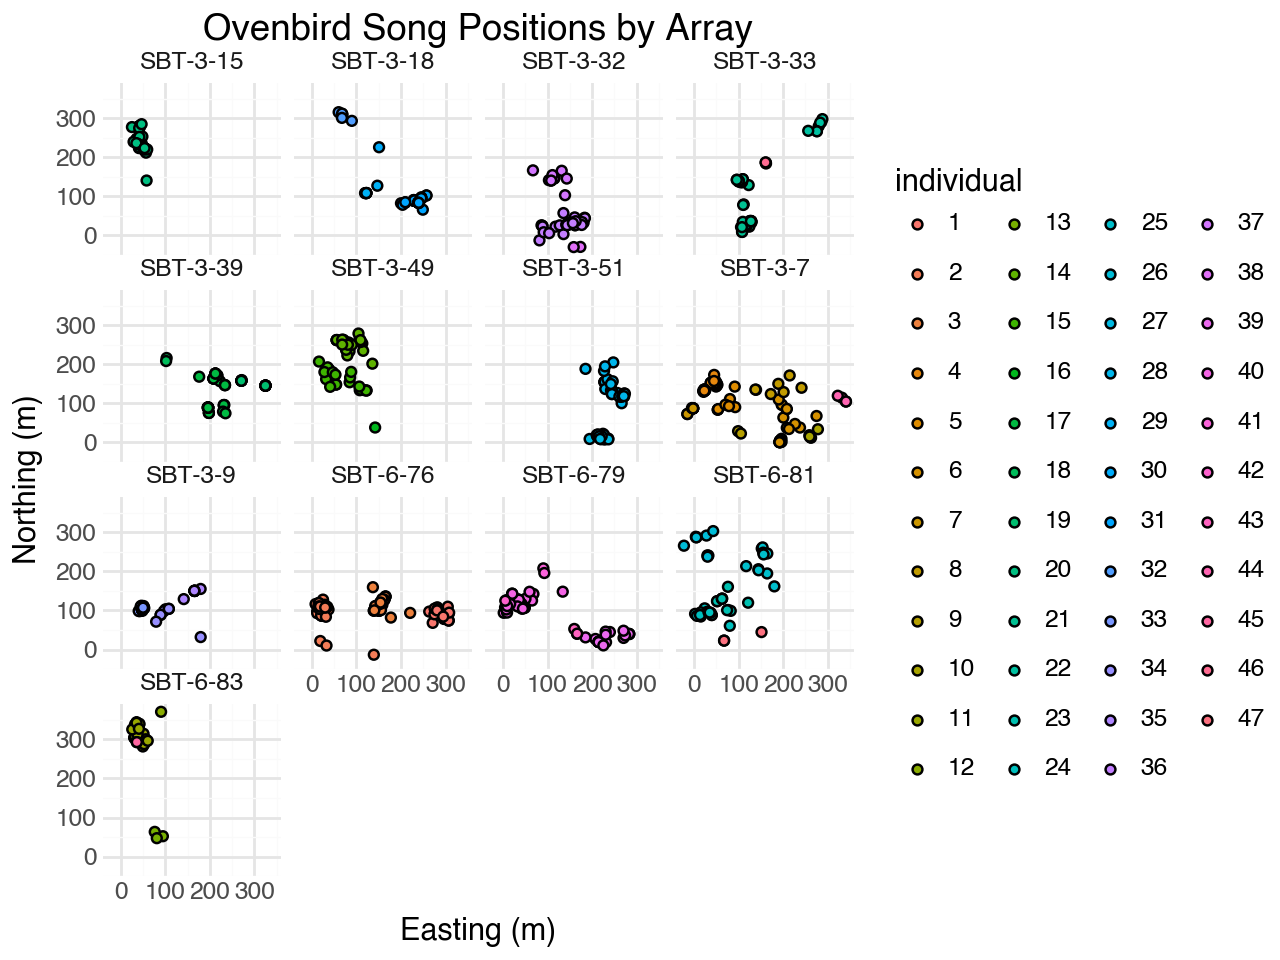

In [253]:
(
    ggplot(fig_df, aes('x', 'y', fill = 'individual')) +
        geom_point() +
        facet_wrap('site') +
        labs(
        title='Ovenbird Song Positions by Array',
        x='Easting (m)',
        y='Northing (m)',
        color='Individual'    
        ) +
        theme_minimal()
)

### Bird Recordings Overlap
The overlaps of all the bird recordings will be found, and that information will be used to determine bird interactions.
- If two bird recordings overlap, that may or may not be an interaction (further analysis is required)
- If two bird recordings do not overlap, that is not an interaction

In [254]:
#subst_loaded_events_df.iloc[0]
len(subst_loaded_events_df)

717

In [255]:
from pandas import DataFrame

def create_tuple_from_df(df: DataFrame, start: str, end: str):
    return list(df[[start, end]].itertuples(index=True, name=None))

In [256]:
# Create tuple events from the dataframe
tuples_events = create_tuple_from_df(subst_loaded_events_df, 'start_timestamp', 'end_timestamp')
tuples_events

[(0,
  Timestamp('2016-06-25 14:10:54+0000', tz='UTC'),
  Timestamp('2016-06-25 14:13:54+0000', tz='UTC')),
 (1,
  Timestamp('2016-06-25 13:26:09+0000', tz='UTC'),
  Timestamp('2016-06-25 13:29:09+0000', tz='UTC')),
 (2,
  Timestamp('2016-06-22 11:43:15+0000', tz='UTC'),
  Timestamp('2016-06-22 11:46:15+0000', tz='UTC')),
 (3,
  Timestamp('2016-06-25 14:21:48+0000', tz='UTC'),
  Timestamp('2016-06-25 14:24:48+0000', tz='UTC')),
 (4,
  Timestamp('2016-06-25 14:20:15+0000', tz='UTC'),
  Timestamp('2016-06-25 14:23:15+0000', tz='UTC')),
 (5,
  Timestamp('2016-06-23 13:02:57+0000', tz='UTC'),
  Timestamp('2016-06-23 13:05:57+0000', tz='UTC')),
 (6,
  Timestamp('2016-06-25 14:11:24+0000', tz='UTC'),
  Timestamp('2016-06-25 14:14:24+0000', tz='UTC')),
 (7,
  Timestamp('2016-06-22 12:24:06+0000', tz='UTC'),
  Timestamp('2016-06-22 12:27:06+0000', tz='UTC')),
 (8,
  Timestamp('2016-06-25 13:13:51+0000', tz='UTC'),
  Timestamp('2016-06-25 13:16:51+0000', tz='UTC')),
 (9,
  Timestamp('2016-06-22

In [257]:
# Find the overlap from all the events
def overlap(events) -> list[tuple]:
    # We need to find all the ways the events overlap, then return a tuple of event ids 
    events_overlapped: list[tuple] = []
    events = sorted(events, key=lambda x: x[1]) # key must use a function for comparison

    for i, (key_1, _, end_1) in enumerate(events): # We do not care about the start for current event due to sort
        for key_2, start_2, _ in events[i+1:]:  # compare against all later events

            if start_2 < end_1:  # overlap condition
                events_overlapped.append((key_1, key_2))
            else: # start_2 >= end_1, which means there is no overlap
                break  # Sorting invariant, can break out early for speedups
            
    return events_overlapped

In [258]:
# Test that sequence of events
overlaps = overlap(tuples_events)
overlaps

[(339, 340),
 (340, 341),
 (343, 344),
 (343, 345),
 (343, 346),
 (343, 347),
 (344, 345),
 (344, 346),
 (344, 347),
 (344, 349),
 (345, 346),
 (345, 347),
 (345, 349),
 (346, 347),
 (346, 349),
 (346, 364),
 (346, 350),
 (347, 349),
 (347, 364),
 (347, 350),
 (347, 351),
 (349, 364),
 (349, 350),
 (349, 351),
 (364, 350),
 (364, 351),
 (364, 352),
 (350, 351),
 (350, 352),
 (351, 352),
 (354, 355),
 (356, 357),
 (356, 358),
 (357, 358),
 (357, 359),
 (358, 359),
 (358, 360),
 (358, 365),
 (359, 360),
 (359, 365),
 (360, 365),
 (360, 361),
 (360, 362),
 (365, 361),
 (365, 362),
 (361, 362),
 (363, 333),
 (363, 348),
 (333, 348),
 (348, 332),
 (317, 318),
 (317, 319),
 (317, 320),
 (317, 321),
 (317, 322),
 (318, 319),
 (318, 320),
 (318, 321),
 (318, 322),
 (319, 320),
 (319, 321),
 (319, 322),
 (319, 330),
 (320, 321),
 (320, 322),
 (320, 330),
 (321, 322),
 (321, 330),
 (322, 330),
 (322, 324),
 (330, 324),
 (323, 325),
 (323, 326),
 (323, 327),
 (325, 326),
 (325, 327),
 (326, 327),

Naively it works, but the overlap count appears to be very low. This suggests that the individual birds in the sites typically do not interrupt one another.

Now, we should specify upper and lower bounds to increase the overlaps. Eg. Two events overlap if they occurred within x minutes of one another.

In [259]:
# First we need to add a lower and upper bound: Start - Lower & End + Upper. Then, use that for overlaps
# Modify the dataframe, adding those new columns for the algorithm to process 
cols = subst_loaded_events_df.columns
#cols
# Fetch only the necessary columns 
time_df = subst_loaded_events_df[['event_key', 'start_timestamp', 'end_timestamp']]
# Process those columns by adding a new one

lower_s = 10
upper_e = 10

time_df['scale_time_start'] = time_df['start_timestamp'] - pd.to_timedelta(lower_s, unit='minute')
time_df['scale_time_end'] = time_df['end_timestamp'] - pd.to_timedelta(upper_e, unit='minute')

time_df = time_df.set_index("event_key")


At this point, we have sucessfully transformed those columns by adding and subtracting increments

In [260]:
time_df

,start_timestamp,end_timestamp,scale_time_start,scale_time_end
event_key,,,,
0,2016-06-25 14:10:54+00:00,2016-06-25 14:13:54+00:00,2016-06-25 14:00:54+00:00,2016-06-25 14:03:54+00:00
1,2016-06-25 13:26:09+00:00,2016-06-25 13:29:09+00:00,2016-06-25 13:16:09+00:00,2016-06-25 13:19:09+00:00
2,2016-06-22 11:43:15+00:00,2016-06-22 11:46:15+00:00,2016-06-22 11:33:15+00:00,2016-06-22 11:36:15+00:00
3,2016-06-25 14:21:48+00:00,2016-06-25 14:24:48+00:00,2016-06-25 14:11:48+00:00,2016-06-25 14:14:48+00:00
4,2016-06-25 14:20:15+00:00,2016-06-25 14:23:15+00:00,2016-06-25 14:10:15+00:00,2016-06-25 14:13:15+00:00
...,...,...,...,...
712,2016-06-02 12:48:42+00:00,2016-06-02 12:51:42+00:00,2016-06-02 12:38:42+00:00,2016-06-02 12:41:42+00:00
713,2016-06-02 12:42:12+00:00,2016-06-02 12:45:12+00:00,2016-06-02 12:32:12+00:00,2016-06-02 12:35:12+00:00
714,2016-06-02 12:37:00+00:00,2016-06-02 12:40:00+00:00,2016-06-02 12:27:00+00:00,2016-06-02 12:30:00+00:00


In [261]:
tuples_events_scale = create_tuple_from_df(time_df, 'start_timestamp', 'end_timestamp')

Now that we have successfully transformed the original dataframe to reflect a broader range, we will run the overlap algorithm on this.

In [262]:
event_overlapping_ids = overlap(tuples_events_scale) # We now have a list of overlapping event ids
# {event_key, event_1, event_2}
event_overlapping_ids

[(339, 340),
 (340, 341),
 (343, 344),
 (343, 345),
 (343, 346),
 (343, 347),
 (344, 345),
 (344, 346),
 (344, 347),
 (344, 349),
 (345, 346),
 (345, 347),
 (345, 349),
 (346, 347),
 (346, 349),
 (346, 364),
 (346, 350),
 (347, 349),
 (347, 364),
 (347, 350),
 (347, 351),
 (349, 364),
 (349, 350),
 (349, 351),
 (364, 350),
 (364, 351),
 (364, 352),
 (350, 351),
 (350, 352),
 (351, 352),
 (354, 355),
 (356, 357),
 (356, 358),
 (357, 358),
 (357, 359),
 (358, 359),
 (358, 360),
 (358, 365),
 (359, 360),
 (359, 365),
 (360, 365),
 (360, 361),
 (360, 362),
 (365, 361),
 (365, 362),
 (361, 362),
 (363, 333),
 (363, 348),
 (333, 348),
 (348, 332),
 (317, 318),
 (317, 319),
 (317, 320),
 (317, 321),
 (317, 322),
 (318, 319),
 (318, 320),
 (318, 321),
 (318, 322),
 (319, 320),
 (319, 321),
 (319, 322),
 (319, 330),
 (320, 321),
 (320, 322),
 (320, 330),
 (321, 322),
 (321, 330),
 (322, 330),
 (322, 324),
 (330, 324),
 (323, 325),
 (323, 326),
 (323, 327),
 (325, 326),
 (325, 327),
 (326, 327),

In [263]:
list(subst_loaded_events_df.columns)

['array',
 'data_split',
 'relative_position',
 'mic_distances_m',
 'start_timestamp',
 'duration',
 'ovenbird_cluster_labels',
 'baseline_resnet18_cluster_labels',
 'hawkears_cluster_labels',
 'birdnet_cluster_labels',
 'individual',
 'end_timestamp',
 'event_key',
 'count']

### Identifying Individuals
Using the unique event ids, we will find the corresponding individuals and plot only those events that occurred at the same time.

In [264]:
# Fetch the rows that correspond to the individuals that have overlapped
individuals = [] # (individual_1, individual_2)
for id in event_overlapping_ids:
    e_1 = subst_loaded_events_df.loc[id[0]]
    e_2 = subst_loaded_events_df.loc[id[1]]

    ind_event_1 = e_1["individual"]
    ind_event_2 = e_2["individual"]

    b_1 = int(ind_event_1)  # type: ignore
    b_2 = int(ind_event_2) # type: ignore

    if e_1["array"] != e_2["array"] or b_1 == b_2: # Check that the site is the same and bird is unique
        continue 
    
    individuals.append( # append the bird & it's row info so we do not have to search again
        (
        {
            "name": b_1,
            "info": e_1
        },
        {
            "name": b_2,
            "info": e_2
        }
        )
    )

In [265]:
individuals

[({'name': 14,
   'info': array                                                                        SBT-3-49
   data_split                                                                        val
   relative_position                                          [84.40235795, 233.3156532]
   mic_distances_m                     [51.59680951456556, 83.60619344784311, 65.4486...
   start_timestamp                                             2016-05-28 12:11:27+00:00
   duration                                                              0 days 00:03:00
   ovenbird_cluster_labels                                                            12
   baseline_resnet18_cluster_labels                                                   10
   hawkears_cluster_labels                                                            10
   birdnet_cluster_labels                                                             14
   individual                                                                         1

Now we have a list of the individuals with overlapping acoustic records, we have enough information to create visualization of the graphs.

Import the networkX library in order to store the individuals into the graph.

In [266]:
import networkx as nx

In [267]:
# Now we can iterate over the list of tuples, adding them to the Graph
# ({name, info}, {name, info}) : These two individual birds had an event overlap, each with its own metadata
bird_net = nx.Graph()
#individuals

for overlap in individuals:
    a = overlap[0]["name"]
    b = overlap[1]["name"]
    
    bird_net.add_node(a)
    bird_net.add_node(b)

    if bird_net.has_edge(a, b):
        bird_net[a][b]["weight"] += 1  # increment on repeat overlap
    else:
        bird_net.add_edge(a, b, weight=1)

In [268]:
print(len(individuals))
print(bird_net.number_of_edges())

258
40


In [269]:
for u, v, data in bird_net.edges(data=True):
    print(u, v, data)
    break

14 15 {'weight': 12}


In [270]:
print(max(data["weight"] for _, _, data in bird_net.edges(data=True)))

36


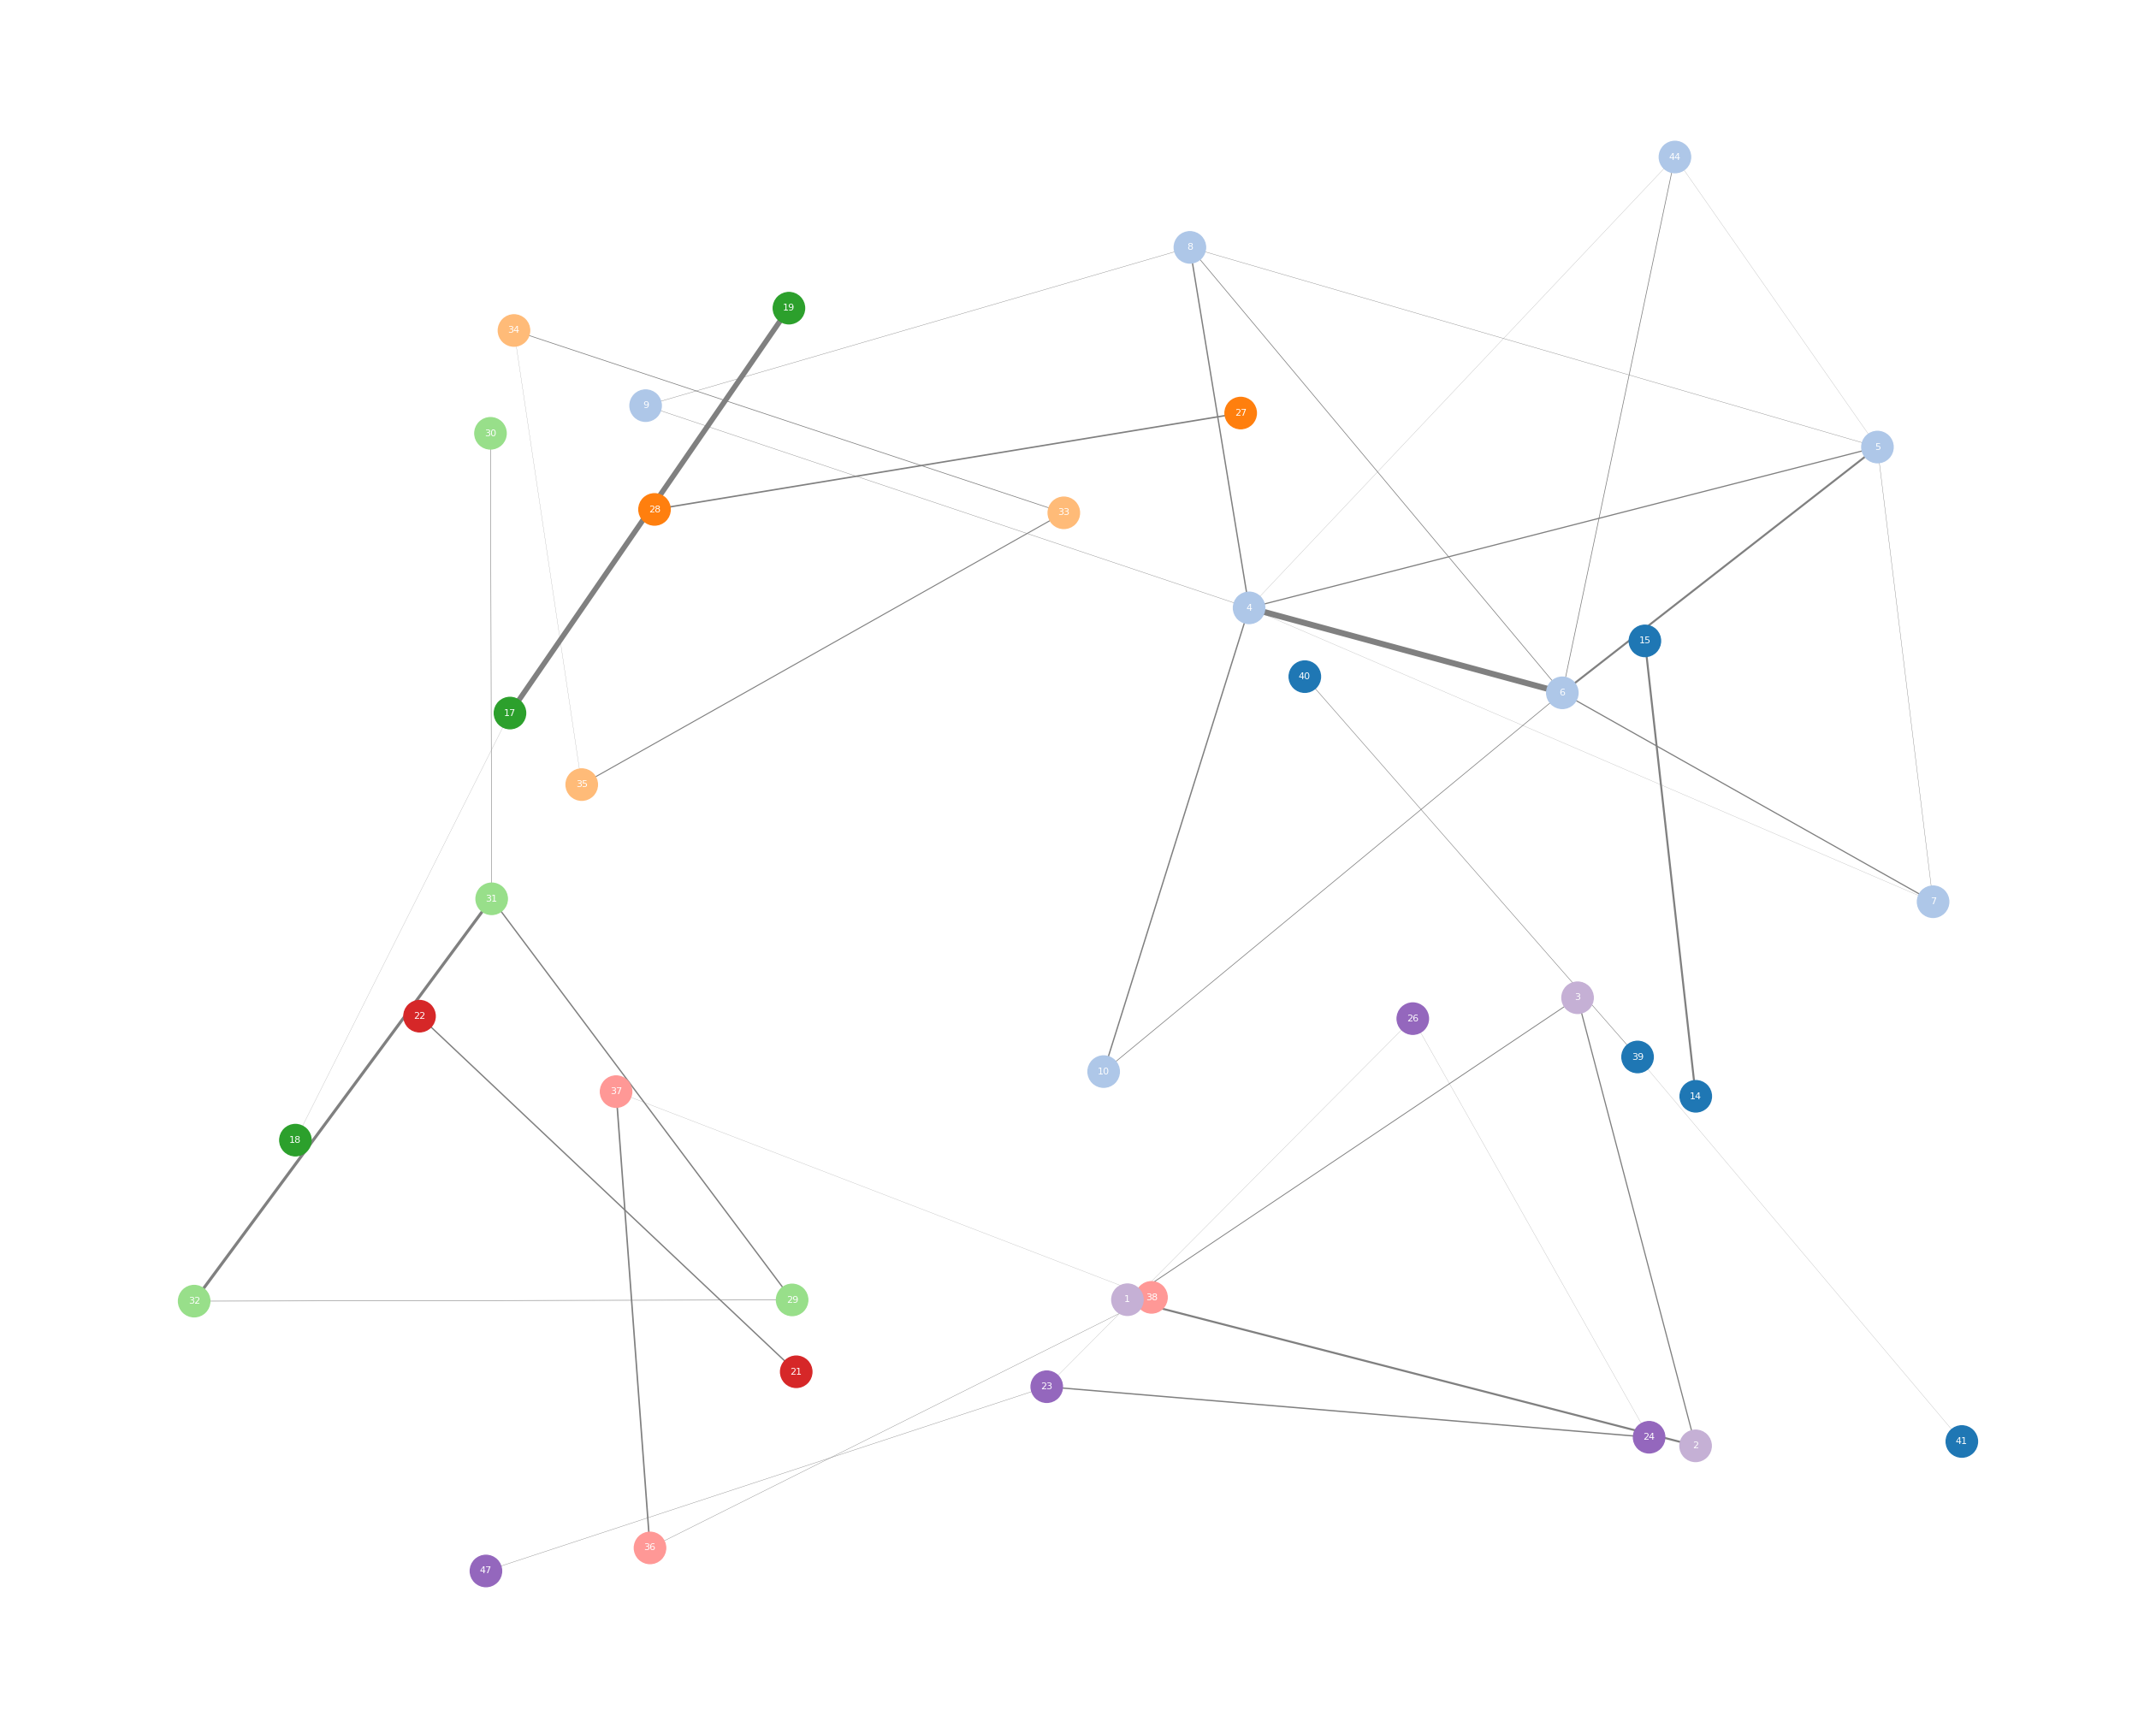

In [271]:
import matplotlib.pyplot as plt
import networkx as nx

components = list(nx.connected_components(bird_net))

cmap = plt.get_cmap("tab20") # 10 distinct colors

# Map each node to its component's color
color_map = {}
for i, component in enumerate(components):
    for node in component:
        color_map[node] = cmap(i % 10)

node_colors = [color_map[node] for node in bird_net.nodes()]
pos = nx.kamada_kawai_layout(bird_net, scale=5, weight=None)      

weights = [bird_net[u][v]["weight"] for u, v in bird_net.edges()]
max_weight = max(weights)
norm_weights = [w / max_weight * 5 for w in weights]  # scale to max thickness of 5

plt.figure(figsize=(25, 20))  # also make the figure itself bigger
nx.draw(bird_net, pos,
        with_labels=True,
        node_color=node_colors,
        edge_color="gray",
        node_size=700,        # bigger nodes
        font_size=8,
        font_color="white",
        width=norm_weights)

plt.show()

In [272]:
components = list(nx.connected_components(bird_net))
for i, comp in enumerate(components):
    print(f"Component {i}: {sorted(comp)}")

Component 0: [14, 15]
Component 1: [4, 5, 6, 7, 8, 9, 10, 44]
Component 2: [27, 28]
Component 3: [33, 34, 35]
Component 4: [17, 18, 19]
Component 5: [29, 30, 31, 32]
Component 6: [21, 22]
Component 7: [36, 37, 38]
Component 8: [23, 24, 26, 47]
Component 9: [1, 2, 3]
Component 10: [39, 40, 41]


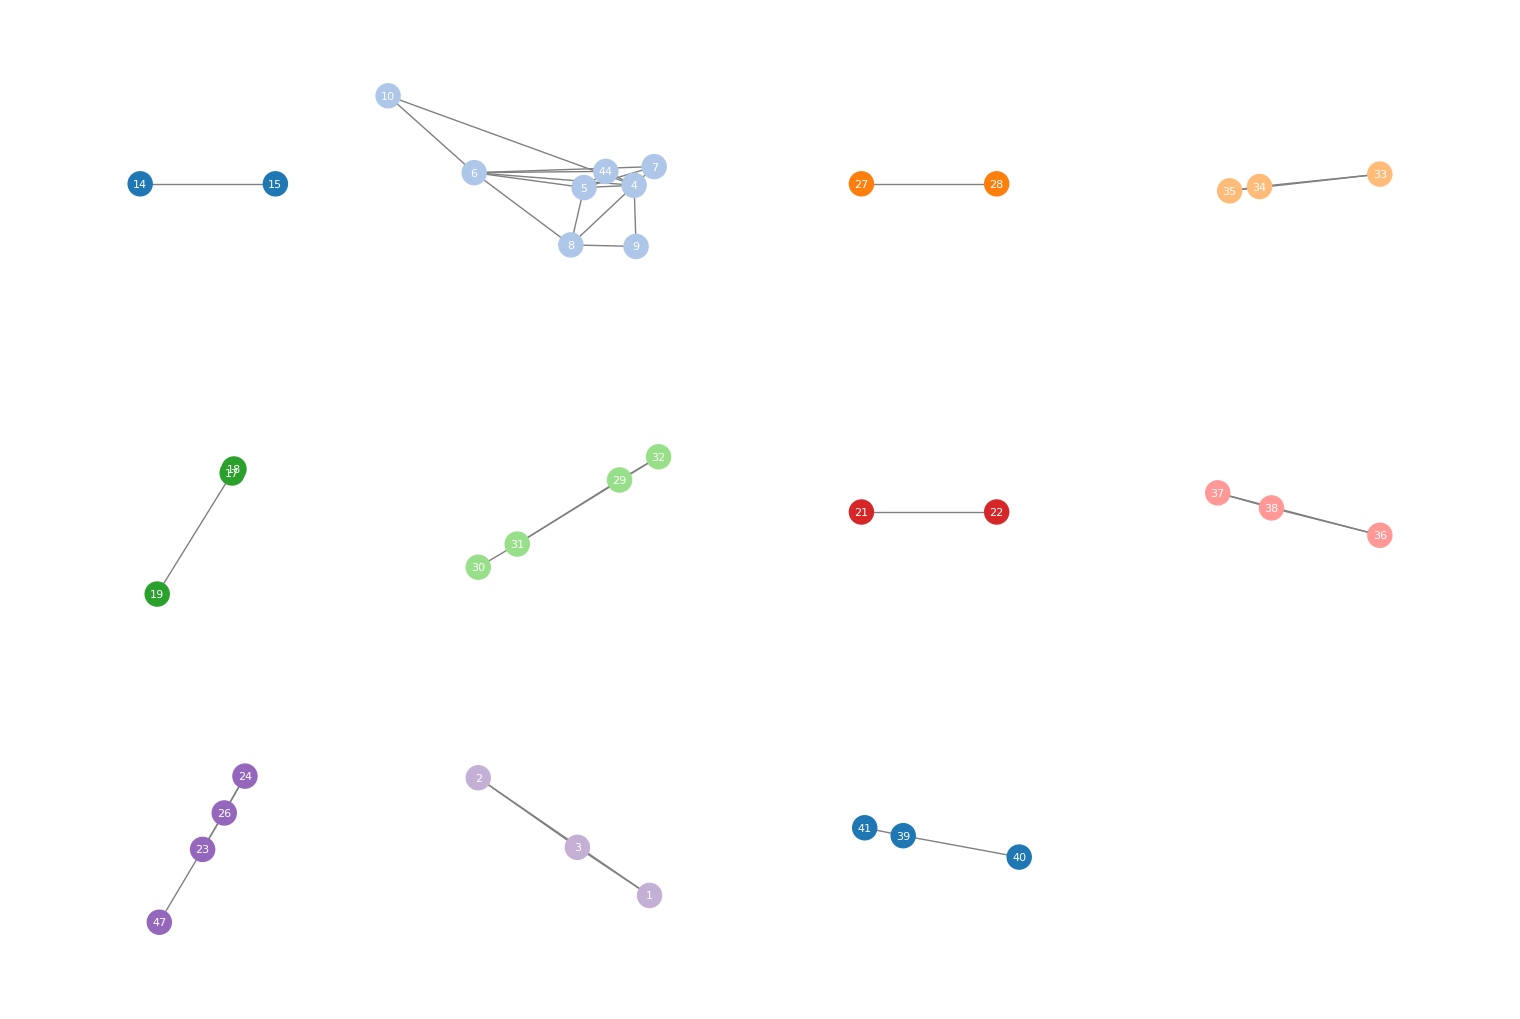

In [273]:
pos = {}
components = list(nx.connected_components(bird_net))

# Place each component in its own region
cols = 4  # number of columns in the grid layout

for i, component in enumerate(components):
    subgraph = bird_net.subgraph(component)
    if len(component) == 2:
        nodes = list(component)
        sub_pos = {nodes[0]: np.array([-1.5, 0]), nodes[1]: np.array([1.5, 0])}
    else: 
        scale = max(2, len(component) * 0.5)  # bigger components get more space
        sub_pos = nx.kamada_kawai_layout(subgraph, scale=scale)
    
    # Offset each component into a grid position
    row, col = divmod(i, cols)
    offset = np.array([col * 8, -row * 8])
    for node, p in sub_pos.items():
        pos[node] = p + offset

plt.figure(figsize=(15, 10))
nx.draw(bird_net, pos,
        with_labels=True,
        node_color=node_colors,
        edge_color="gray",
        node_size=300,
        font_size=8,
        font_color="white")
plt.show()

In [274]:
from pyvis.network import Network
import networkx as nx

In [285]:
# Build a site -> color mapping
site_map = {}  # node -> site
for node in bird_net.nodes():
    site_map[node] = subst_loaded_events_df[
        subst_loaded_events_df["individual"] == node
    ].iloc[0]["array"]

sites = list(set(site_map.values()))
indices = [0, 2, 4, 6, 8, 10, 12, 14, 16, 18, 1]  # 11 distinct indices from tab20
site_colors = {site: cmap(indices[i]) for i, site in enumerate(sites)}

In [286]:
components = list(nx.connected_components(bird_net))
for i, comp in enumerate(components):
    print(f"{sites[i]} {i}: {sorted(comp)}")

SBT-3-51 0: [14, 15]
SBT-6-76 1: [4, 5, 6, 7, 8, 9, 10, 44]
SBT-3-9 2: [27, 28]
SBT-3-33 3: [33, 34, 35]
SBT-3-39 4: [17, 18, 19]
SBT-3-7 5: [29, 30, 31, 32]
SBT-6-79 6: [21, 22]
SBT-3-49 7: [36, 37, 38]
SBT-3-32 8: [23, 24, 26, 47]
SBT-6-81 9: [1, 2, 3]
SBT-3-18 10: [39, 40, 41]


In [287]:
net = Network(notebook=True, height="750px", width="100%")

# Add nodes
for i, component in enumerate(components):
    for node in component:
        site = site_map[node]
        color = site_colors[site]
        hex_color = "#{:02x}{:02x}{:02x}".format(
            int(color[0]*255), int(color[1]*255), int(color[2]*255)
        )
        net.add_node(node,
                     label=str(node),
                     color=hex_color,
                     font={"size": 14, "color": "black", "align": "center"})

# Add edges with normalized weights
weights = [data.get("weight", 1) for _, _, data in bird_net.edges(data=True)]
min_w, max_w = min(weights), max(weights)

for src, dest, data in bird_net.edges(data=True):
    w = data.get("weight", 1)
    normalized = 1 + 14 * (w - min_w) / (max_w - min_w)
    net.add_edge(src, dest, value=normalized)

net.show_buttons(filter_=["physics"])
net.show("bird_net.html")

bird_net.html


In [284]:
for site, color in site_colors.items():
    hex_color = "#{:02x}{:02x}{:02x}".format(
        int(color[0]*255), int(color[1]*255), int(color[2]*255)
    )
    print(site, hex_color)

SBT-3-51 #1f77b4
SBT-6-76 #ff7f0e
SBT-3-9 #2ca02c
SBT-3-33 #d62728
SBT-3-39 #9467bd
SBT-3-7 #8c564b
SBT-6-79 #e377c2
SBT-3-49 #7f7f7f
SBT-3-32 #bcbd22
SBT-6-81 #17becf
SBT-3-18 #1f77b4
